In [1]:
import pandas as pd

In [2]:
main_df=pd.read_csv("Featured_dataset.csv")
main_df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,...,Estimated_Annual_Spend,Loyalty_Score_scaled,Promo_Dependency,Annual_Spend,Value_Tier,Customer_Value_Index,Satisfaction_Level,Tenure_Proxy,Bargain_Hunter,ICS_scaled
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,1378,50.220088,2,1378,High Value,854.36,Medium,New,1,36.681798
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,1664,40.424170,2,1664,Premium Value,1031.68,Medium,New,1,33.716271
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,3796,77.959184,2,3796,Premium Value,2353.52,Medium,Growing,1,56.693105
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,4680,99.183673,2,4680,Premium Value,3276.00,Medium,Veteran,1,78.078323
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,49,44.489796,2,49,Low Value,26.46,Low,Veteran,1,29.840844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,...,1456,65.306122,0,1456,High Value,1223.04,High,Veteran,0,42.755764
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,...,1274,52.260904,0,1274,High Value,1146.60,High,Veteran,0,48.799504
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,...,132,21.128451,0,132,Low Value,76.56,Low,Growing,0,14.944512
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,...,4004,58.775510,0,4004,Premium Value,3043.04,Medium,Growing,0,51.906674


In [3]:
import pandas as pd
import numpy as np
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [4]:
df=main_df.copy(deep=True)
df

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,...,Estimated_Annual_Spend,Loyalty_Score_scaled,Promo_Dependency,Annual_Spend,Value_Tier,Customer_Value_Index,Satisfaction_Level,Tenure_Proxy,Bargain_Hunter,ICS_scaled
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,1378,50.220088,2,1378,High Value,854.36,Medium,New,1,36.681798
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,1664,40.424170,2,1664,Premium Value,1031.68,Medium,New,1,33.716271
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,3796,77.959184,2,3796,Premium Value,2353.52,Medium,Growing,1,56.693105
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,4680,99.183673,2,4680,Premium Value,3276.00,Medium,Veteran,1,78.078323
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,49,44.489796,2,49,Low Value,26.46,Low,Veteran,1,29.840844
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3895,3896,40,Female,Hoodie,Clothing,28,Virginia,L,Turquoise,Summer,...,1456,65.306122,0,1456,High Value,1223.04,High,Veteran,0,42.755764
3896,3897,52,Female,Backpack,Accessories,49,Iowa,L,White,Spring,...,1274,52.260904,0,1274,High Value,1146.60,High,Veteran,0,48.799504
3897,3898,46,Female,Belt,Accessories,33,New Jersey,L,Green,Spring,...,132,21.128451,0,132,Low Value,76.56,Low,Growing,0,14.944512
3898,3899,44,Female,Shoes,Footwear,77,Minnesota,S,Brown,Summer,...,4004,58.775510,0,4004,Premium Value,3043.04,Medium,Growing,0,51.906674


In [5]:
df[['Promo Code Used','Estimated_Annual_Spend']].groupby(by='Promo Code Used').mean()

,Estimated_Annual_Spend
Promo Code Used,
0,1041.743140
1,1035.202147


In [6]:
df['Estimated_Annual_Spend']

0       1378
1       1664
2       3796
3       4680
4         49
        ... 
3895    1456
3896    1274
3897     132
3898    4004
3899     324
Name: Estimated_Annual_Spend, Length: 3900, dtype: int64

In [7]:
spend_promo = df[df['Promo Code Used'] == 1]['Purchase Amount (USD)']
spend_promo

0       53
1       64
2       73
3       90
4       49
        ..
1672    73
1673    62
1674    56
1675    90
1676    44
Name: Purchase Amount (USD), Length: 1677, dtype: int64

In [8]:
spend_promo = df[df['Promo Code Used'] == 1]['Purchase Amount (USD)']
spend_no_promo = df[df['Promo Code Used'] == 0]['Purchase Amount (USD)']
t_stat, t_pval = stats.ttest_ind(spend_promo, spend_no_promo, equal_var=False)
print(f"[Welch's t-test] Spend vs Promo: t-stat = {t_stat:.4f}, p-value = {t_pval:.4f}")

[Welch's t-test] Spend vs Promo: t-stat = -1.1122, p-value = 0.2661


In [9]:
group2 = df[df['Promo_Dependency'] == 2]['Review Rating']
group2

0       3.1
1       3.1
2       3.1
3       3.5
4       2.7
       ... 
1672    3.8
1673    3.4
1674    3.2
1675    4.7
1676    3.1
Name: Review Rating, Length: 1677, dtype: float64

In [10]:
import scipy.stats as stats

# Group customer review ratings by their assigned Value Tier
vt_groups = [group['Review Rating'].dropna() for name, group in df.groupby('Value_Tier')]

# Run One-Way ANOVA
f_stat, p_val = stats.f_oneway(*vt_groups)

print(f"F-statistic = {f_stat:.4f}, p-value = {p_val:.4f}")

F-statistic = 0.8370, p-value = 0.4734


In [11]:
# C. Chi-Square Test: Subscription Status vs Discount Applied
contingency_tab = pd.crosstab(df['Subscription Status'], df['Discount Applied'])
chi2, chi_pval, dof, _ = stats.chi2_contingency(contingency_tab)
print(f"[Chi-Square] Subscription vs Discount: Chi2 = {chi2:.4f}, p-value = {chi_pval:.4f}")

[Chi-Square] Subscription vs Discount: Chi2 = 1908.9214, p-value = 0.0000


In [12]:
#customer segment level: Value_Tier vs Discount Applied
contingency_vt = pd.crosstab(df['Value_Tier'], df['Discount Applied'])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency_vt)
print(f"Chi2 = {chi2:.4f}, p-value = {p_val:.4f}")

Chi2 = 0.1842, p-value = 0.9801


In [13]:
#Category vs Discount Applied (Product Level)
contingency_cat = pd.crosstab(df['Category'], df['Discount Applied'])
chi2, p_val, dof, _ = stats.chi2_contingency(contingency_cat)
print(f"Chi2 = {chi2:.4f}, p-value = {p_val:.4f}")

Chi2 = 1.2003, p-value = 0.7529


--- K-Means Evaluation Metrics ---
K= 2 | WCSS (Inertia):   18532.61 | Silhouette: 0.2035 | Calinski-Harabasz: 1023.77
K= 3 | WCSS (Inertia):   15921.76 | Silhouette: 0.1772 | Calinski-Harabasz:  915.19
K= 4 | WCSS (Inertia):   14425.50 | Silhouette: 0.1640 | Calinski-Harabasz:  807.95
K= 5 | WCSS (Inertia):   13172.12 | Silhouette: 0.1660 | Calinski-Harabasz:  756.10
K= 6 | WCSS (Inertia):   12277.60 | Silhouette: 0.1644 | Calinski-Harabasz:  705.53
K= 7 | WCSS (Inertia):   11593.38 | Silhouette: 0.1610 | Calinski-Harabasz:  660.77
K= 8 | WCSS (Inertia):   10919.75 | Silhouette: 0.1664 | Calinski-Harabasz:  635.46
K= 9 | WCSS (Inertia):   10268.84 | Silhouette: 0.1748 | Calinski-Harabasz:  621.96
K=10 | WCSS (Inertia):    9680.84 | Silhouette: 0.1789 | Calinski-Harabasz:  612.52


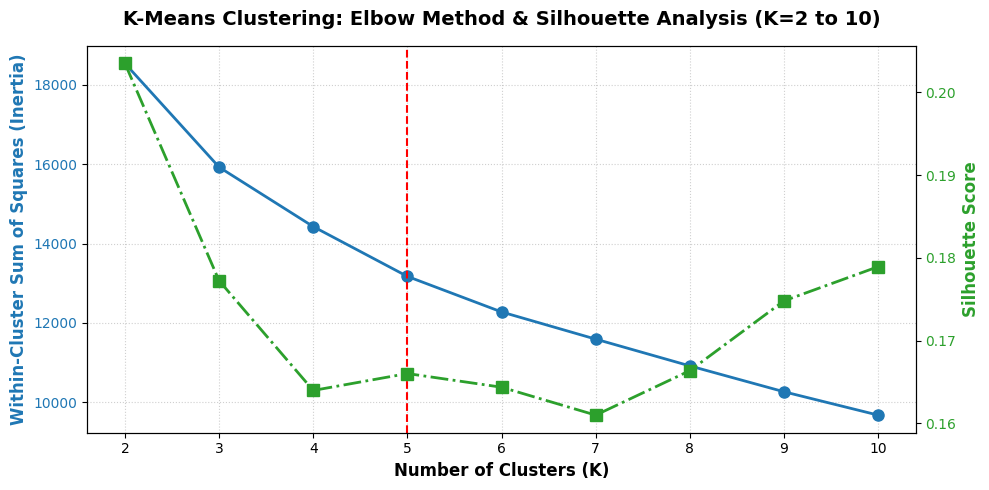

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

# 1. Load the engineered dataset
df = pd.read_csv("Featured_dataset.csv")

# 2. Select numerical features for K-Means clustering
cluster_features = [
    'Age', 
    'Purchase Amount (USD)', 
    'Review Rating', 
    'Previous Purchases', 
    'Purchase_Freq_Score', 
    'Loyalty_Score_scaled'
]

X = df[cluster_features]

# 3. Standardize features to mean=0, std=1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Iterate K-Means across K = 2 to 10
K_range = range(2, 11)
inertias = []
silhouettes = []
ch_scores = []

print("--- K-Means Evaluation Metrics ---")
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    
    wcss = km.inertia_
    sil = silhouette_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    
    inertias.append(wcss)
    silhouettes.append(sil)
    ch_scores.append(ch)
    
    print(f"K={k:2d} | WCSS (Inertia): {wcss:10.2f} | Silhouette: {sil:.4f} | Calinski-Harabasz: {ch:7.2f}")

# 5. Plot the Elbow Curve & Silhouette Scores
fig, ax1 = plt.subplots(figsize=(10, 5))

# Plot Inertia (WCSS) on left axis
color = 'tab:blue'
ax1.set_xlabel('Number of Clusters (K)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Within-Cluster Sum of Squares (Inertia)', color=color, fontsize=12, fontweight='bold')
ax1.plot(K_range, inertias, marker='o', color=color, linewidth=2, markersize=8, label='Inertia (WCSS)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.axvline(x=5, color='red', linestyle='--', linewidth=1.5, label='Selected K=5')
ax1.grid(True, linestyle=':', alpha=0.6)

# Plot Silhouette Score on right axis
ax2 = ax1.twinx()  
color = 'tab:green'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=12, fontweight='bold')
ax2.plot(K_range, silhouettes, marker='s', color=color, linewidth=2, markersize=8, linestyle='-.', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('K-Means Clustering: Elbow Method & Silhouette Analysis (K=2 to 10)', fontsize=14, fontweight='bold', pad=15)
fig.tight_layout()
plt.show()

=== CLUSTER PROFILE ===
                           Persona  Customer_Pct  Revenue_Pct  Revenue_Share_Ratio  Avg_Age  Avg_Purchase_Amount  Avg_Review_Rating  Avg_Previous_Purchases  Avg_Freq_Score  Avg_Loyalty  Discount_Rate  Avg_Annual_Spend
0        Weekly Power Buyers (VIP)         13.92        40.94                 2.94    44.66                58.95               3.76                   25.76           51.81        65.99           0.44           3054.74
2       High-Basket Loyal Shoppers         21.54        22.34                 1.04    45.02                81.59               3.86                   37.56           13.21        45.73           0.45           1077.50
1    Young Low-Engagement Shoppers         21.67        14.05                 0.65    29.54                60.22               3.89                   13.33           11.33        22.43           0.40            673.49
4      Older Low-Engagement Buyers         21.56        12.34                 0.57    57.52             

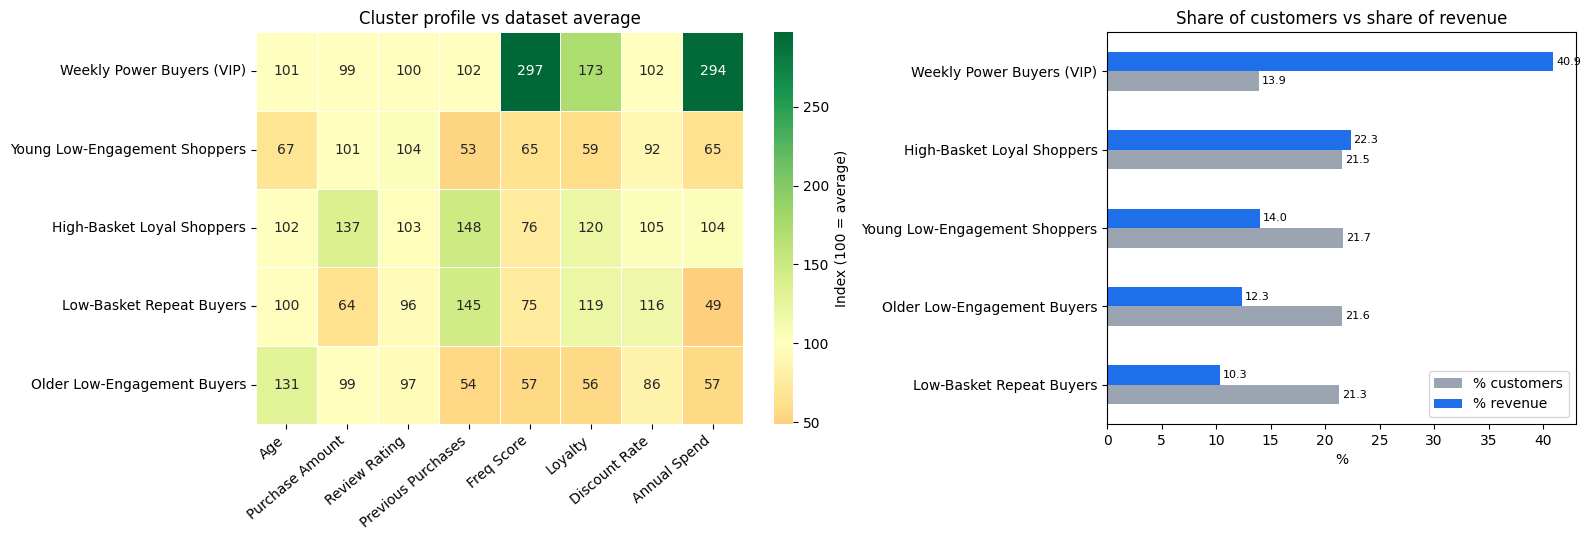

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# ------------------------------------------------------------------
# Load and cluster
# ------------------------------------------------------------------
df = pd.read_csv("Featured_dataset.csv")

features = ['Age', 'Purchase Amount (USD)', 'Review Rating',
            'Previous Purchases', 'Purchase_Freq_Score', 'Loyalty_Score_scaled']

X_scaled = StandardScaler().fit_transform(df[features])
km = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster'] = km.fit_predict(X_scaled)

# ------------------------------------------------------------------
# Profile table (one row per cluster)
# ------------------------------------------------------------------
total_rev = df['Estimated_Annual_Spend'].sum()

profile = df.groupby('Cluster').agg(
    Customers=('Customer ID', 'count'),
    Avg_Age=('Age', 'mean'),
    Avg_Purchase_Amount=('Purchase Amount (USD)', 'mean'),
    Avg_Review_Rating=('Review Rating', 'mean'),
    Avg_Previous_Purchases=('Previous Purchases', 'mean'),
    Avg_Freq_Score=('Purchase_Freq_Score', 'mean'),
    Avg_Loyalty=('Loyalty_Score_scaled', 'mean'),
    Discount_Rate=('Discount Applied', 'mean'),   # works if it is 0/1; see note below
    Avg_Annual_Spend=('Estimated_Annual_Spend', 'mean'),
    Total_Revenue=('Estimated_Annual_Spend', 'sum'),
)
profile['Customer_Pct'] = profile['Customers'] / len(df) * 100
profile['Revenue_Pct'] = profile['Total_Revenue'] / total_rev * 100
profile['Revenue_Share_Ratio'] = profile['Revenue_Pct'] / profile['Customer_Pct']

# ------------------------------------------------------------------
# Labels derived from the profile (not hardcoded cluster IDs)
# ------------------------------------------------------------------
labels = {}
weekly = profile['Avg_Freq_Score'].idxmax()
labels[weekly] = 'Weekly Power Buyers (VIP)'

rest = profile.drop(index=weekly)
hi_basket = rest['Avg_Purchase_Amount'].idxmax()
lo_basket = rest['Avg_Purchase_Amount'].idxmin()
labels[hi_basket] = 'High-Basket Loyal Shoppers'
labels[lo_basket] = 'Low-Basket Repeat Buyers'

rest2 = rest.drop(index=[hi_basket, lo_basket])
labels[rest2['Avg_Age'].idxmin()] = 'Young Low-Engagement Shoppers'
labels[rest2['Avg_Age'].idxmax()] = 'Older Low-Engagement Buyers'

assert len(set(labels.values())) == 5, "Label rules collided - inspect the profile table"

profile['Persona'] = profile.index.map(labels)
df['Persona'] = df['Cluster'].map(labels)

# ------------------------------------------------------------------
#  Baseline row + printed profile
# ------------------------------------------------------------------
baseline = {
    'Avg_Age': df['Age'].mean(),
    'Avg_Purchase_Amount': df['Purchase Amount (USD)'].mean(),
    'Avg_Review_Rating': df['Review Rating'].mean(),
    'Avg_Previous_Purchases': df['Previous Purchases'].mean(),
    'Avg_Freq_Score': df['Purchase_Freq_Score'].mean(),
    'Avg_Loyalty': df['Loyalty_Score_scaled'].mean(),
    'Discount_Rate': df['Discount Applied'].mean(),
    'Avg_Annual_Spend': df['Estimated_Annual_Spend'].mean(),
}

show_cols = ['Persona', 'Customer_Pct', 'Revenue_Pct', 'Revenue_Share_Ratio',
             'Avg_Age', 'Avg_Purchase_Amount', 'Avg_Review_Rating',
             'Avg_Previous_Purchases', 'Avg_Freq_Score', 'Avg_Loyalty',
             'Discount_Rate', 'Avg_Annual_Spend']

out = profile[show_cols].sort_values('Revenue_Pct', ascending=False).round(2)
base_row = pd.DataFrame([{**baseline, 'Persona': 'OVERALL BASELINE',
                          'Customer_Pct': 100.0, 'Revenue_Pct': 100.0,
                          'Revenue_Share_Ratio': 1.0}], index=['ALL'])[show_cols].round(2)

print("=== CLUSTER PROFILE ===")
print(pd.concat([out, base_row]).to_string())


# ------------------------------------------------------------------
# Charts
# ------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5),
                         gridspec_kw={'width_ratios': [1.3, 1]})

# (a) Heatmap of index vs baseline
sns.heatmap(index_df.round(0), annot=True, fmt='.0f', cmap='RdYlGn', center=100,
            linewidths=0.5, cbar_kws={'label': 'Index (100 = average)'}, ax=axes[0])
axes[0].set_title('Cluster profile vs dataset average')
axes[0].set_ylabel('')
axes[0].set_xticklabels([c.replace('Avg_', '').replace('_', ' ')
                         for c in idx_cols], rotation=40, ha='right')

# (b) Customer share vs revenue share
share = profile.set_index('Persona')[['Customer_Pct', 'Revenue_Pct']] \
               .sort_values('Revenue_Pct', ascending=True)
share.plot(kind='barh', ax=axes[1], color=['#9aa5b1', '#1f6feb'])
axes[1].set_title('Share of customers vs share of revenue')
axes[1].set_xlabel('%')
axes[1].set_ylabel('')
axes[1].legend(['% customers', '% revenue'])
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f', padding=2, fontsize=8)

plt.tight_layout()
plt.savefig("cluster_profile.png", dpi=200, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------------
# 7. Export so SQL / Power BI use the same assignments
# ------------------------------------------------------------------
df.to_csv("Featured_dataset_with_clusters.csv", index=False)
profile.reset_index().to_csv("cluster_profile_table.csv", index=False)